# Medical Appointment No-Show Prediction

## Project objective
Build a supervised machine learning classification model that estimates the probability that a patient will miss a scheduled appointment also to Understand missed medical appointments and help clinics identify appointments at higher risk of a no-show.

## Problem type: 
Supervised learning Classification.

### Target: 
No-show.

## Table of Contents

1. Data Inspection

2. Data Cleaning

3. Exploratory Data Analysis and Visualization

4. Separate Features x and Target y

5. Split Train and Test Data

6. Preprocessing : Encoding and Scaling

7. Model Training, Prediction and Evaluation

8. Model Comparison and Hyperparameter Tuning

9. Final Model and New Predictions

10. Deployment

In [3]:
import pandas as pd
import numpy as np

### Data Inspection 

In [5]:
df = pd.read_csv("KaggleV2-May-2016.csv")

In [6]:
df.head()

,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,2.987250e+13,5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,5.589978e+14,5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4.262962e+12,5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,8.679512e+11,5642828,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,8.841186e+12,5642494,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,1,1,0,0,0,No


In [46]:
#list of all the available column names (WaitingDays\calendar_wait was created to add to the df)

df.columns

Index(['PatientId', 'AppointmentID', 'Gender', 'ScheduledDay',
       'AppointmentDay', 'Age', 'Neighbourhood', 'Scholarship', 'Hipertension',
       'Diabetes', 'Alcoholism', 'Handcap', 'SMS_received', 'No-show',
       'WaitingDays'],
      dtype='object')

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 110527 entries, 0 to 110526
Data columns (total 14 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   PatientId       110527 non-null  float64
 1   AppointmentID   110527 non-null  int64  
 2   Gender          110527 non-null  object 
 3   ScheduledDay    110527 non-null  object 
 4   AppointmentDay  110527 non-null  object 
 5   Age             110527 non-null  int64  
 6   Neighbourhood   110527 non-null  object 
 7   Scholarship     110527 non-null  int64  
 8   Hipertension    110527 non-null  int64  
 9   Diabetes        110527 non-null  int64  
 10  Alcoholism      110527 non-null  int64  
 11  Handcap         110527 non-null  int64  
 12  SMS_received    110527 non-null  int64  
 13  No-show         110527 non-null  object 
dtypes: float64(1), int64(8), object(5)
memory usage: 11.8+ MB


In [47]:
# the train dataset contains 110,526, row and 14 columns + WaitingDays\calendar_wait which was created and added, total 15 column
df.shape

(110526, 15)

In [8]:
df.describe()

,PatientId,AppointmentID,Age,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received
count,1.105270e+05,1.105270e+05,110527.000000,110527.000000,110527.000000,110527.000000,110527.000000,110527.000000,110527.000000
mean,1.474963e+14,5.675305e+06,37.088874,0.098266,0.197246,0.071865,0.030400,0.022248,0.321026
std,2.560949e+14,7.129575e+04,23.110205,0.297675,0.397921,0.258265,0.171686,0.161543,0.466873
min,3.921784e+04,5.030230e+06,-1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,4.172614e+12,5.640286e+06,18.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,3.173184e+13,5.680573e+06,37.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,9.439172e+13,5.725524e+06,55.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
max,9.999816e+14,5.790484e+06,115.000000,1.000000,1.000000,1.000000,1.000000,4.000000,1.000000


In [9]:
# give me statistics of object dtypes only 
df.describe(include="object")

,Gender,ScheduledDay,AppointmentDay,Neighbourhood,No-show
count,110527,110527,110527,110527,110527
unique,2,103549,27,81,2
top,F,2016-05-06T07:09:54Z,2016-06-06T00:00:00Z,JARDIM CAMBURI,No
freq,71840,24,4692,7717,88208


In [10]:
#Check for Duplicate Rows
df.duplicated().sum()

np.int64(0)

In [11]:
#Check for Missing Value
df.isnull().sum()

PatientId         0
AppointmentID     0
Gender            0
ScheduledDay      0
AppointmentDay    0
Age               0
Neighbourhood     0
Scholarship       0
Hipertension      0
Diabetes          0
Alcoholism        0
Handcap           0
SMS_received      0
No-show           0
dtype: int64

In [12]:
df.dtypes

PatientId         float64
AppointmentID       int64
Gender             object
ScheduledDay       object
AppointmentDay     object
Age                 int64
Neighbourhood      object
Scholarship         int64
Hipertension        int64
Diabetes            int64
Alcoholism          int64
Handcap             int64
SMS_received        int64
No-show            object
dtype: object

## Data Cleaning

In [14]:
#Convert Date Columns "ScheduledDay" to real panda datetime

df["ScheduledDay"] = pd.to_datetime(df["ScheduledDay"])

In [15]:
#Convert Date Columns "AppointmentDay" to real panda datetime

df["AppointmentDay"] = pd.to_datetime(df["AppointmentDay"])

In [16]:
#Verify Data Types Again to confirm if any age is less than 0
df[df["Age"] < 0]

,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
99832,4.659432e+14,5775010,F,2016-06-06 08:58:13+00:00,2016-06-06 00:00:00+00:00,-1,ROMÃO,0,0,0,0,0,0,No


In [17]:
# We found age that is -0, Since age cannot be negative, this record is invalid and should be removed. 

#Clean the invalid record ansd applying back to dataframe
df = df[df["Age"] >= 0]

In [18]:
#Verify the result
df[df["Age"] < 0]

,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show


In [19]:
# how many unique in gender volumn, we have F which stand for Female and M which stand for Male 
df["Gender"].unique()

array(['F', 'M'], dtype=object)

In [21]:
# what are the uiquue in No-show column ( we have No or Yes)
df["No-show"].unique()

array(['No', 'Yes'], dtype=object)

In [20]:
# what are the uiquue in Neighbourhood column ( 81)

df["Neighbourhood"].nunique()

81

In [21]:
# show all the values that uniques under Neighborhood column and sort it 
df["Neighbourhood"].sort_values().unique()

array(['AEROPORTO', 'ANDORINHAS', 'ANTÔNIO HONÓRIO',
       'ARIOVALDO FAVALESSA', 'BARRO VERMELHO', 'BELA VISTA',
       'BENTO FERREIRA', 'BOA VISTA', 'BONFIM', 'CARATOÍRA', 'CENTRO',
       'COMDUSA', 'CONQUISTA', 'CONSOLAÇÃO', 'CRUZAMENTO', 'DA PENHA',
       'DE LOURDES', 'DO CABRAL', 'DO MOSCOSO', 'DO QUADRO',
       'ENSEADA DO SUÁ', 'ESTRELINHA', 'FONTE GRANDE', 'FORTE SÃO JOÃO',
       'FRADINHOS', 'GOIABEIRAS', 'GRANDE VITÓRIA', 'GURIGICA', 'HORTO',
       'ILHA DAS CAIEIRAS', 'ILHA DE SANTA MARIA', 'ILHA DO BOI',
       'ILHA DO FRADE', 'ILHA DO PRÍNCIPE', 'ILHAS OCEÂNICAS DE TRINDADE',
       'INHANGUETÁ', 'ITARARÉ', 'JABOUR', 'JARDIM CAMBURI',
       'JARDIM DA PENHA', 'JESUS DE NAZARETH', 'JOANA D´ARC',
       'JUCUTUQUARA', 'MARIA ORTIZ', 'MARUÍPE', 'MATA DA PRAIA',
       'MONTE BELO', 'MORADA DE CAMBURI', 'MÁRIO CYPRESTE', 'NAZARETH',
       'NOVA PALESTINA', 'PARQUE INDUSTRIAL', 'PARQUE MOSCOSO', 'PIEDADE',
       'PONTAL DE CAMBURI', 'PRAIA DO CANTO', 'PRAIA DO SUÁ',

#### Handling missing dates

Handling missing dates

ScheduledDay = when the appointment was booked.
AppointmentDay = when the patient was supposed to attend.

dt.normalize() means The time becomes 00:00:00, but the date stays unchanged.

In [41]:
# We want to check wether diffrences in between the dates column using filtering and normalize that ( reset the time to 00:00)
same_calendar_date = ( df["ScheduledDay"].dt.normalize()  == df["AppointmentDay"].dt.normalize())

print("Same calendar date:", same_calendar_date.sum()) #show the total sum of the same day schedule & appointment we got from the var (same_calendar_date)
print("Appointments on different calendar dates:", (same_calendar_date == False).sum()) # show the total sum,still using the var we got, filtering  with false, any same day that are not true 
print("Same-date percentage:", round(same_calendar_date.mean() * 100, 2), "%") # perentage of patient with same days (34.89%)

Same calendar date: 38562
Different calendar dates: 38562
Same-date percentage: 34.89 %


In [55]:
# created WaitingDays here, it was initially called calendar_wait so they both represnt the same variable WaitingDays\calendar_wait

# trying to check the waiting days for patient before their appointment day so we used our created var called (WaitingDays) and
# subtracts schedule day from appointment day to get the acccuracy datetimes & days 
WaitingDays = (df["AppointmentDay"].dt.normalize() - df["ScheduledDay"].dt.normalize()).dt.days

print("\nDuplicate AppointmentID:", df["AppointmentID"].duplicated().sum()) # any duplicate in appointment id ? we have 0

print("Repeated PatientId rows:", df["PatientId"].duplicated().sum()) # any duplicate in patient id ? we have 48,228

print("\nTarget counts:") # Newline heading Target counts
print(df["No-show"].value_counts(dropna=False)) #show our target value count, no drop just print 

print("\nMissing date values:") # Newline heading Missing date values 
print(df[["ScheduledDay", "AppointmentDay"]].isnull().sum()) # any missing values in ScheduleDay and Appointment day column ? we have 0 in both col

print("\nCalendar waiting-time checks:") # Newline heading Calendar waiting-time checks
print("Negative days:", (calendar_wait < 0).sum()) # checking negative row by using the var (calendar_wait) filtering anything less than 0, we have 5, 
print("Same-day appointments:", (calendar_wait == 0).sum()) # checking same day appointment using the var (calendar_wait) filtering anything equal 0
print("Minimum waiting days:", calendar_wait.min()) # show the min in the var (calendar_wait), result is negative -6, show inconsistence so we removing the 5 row valuesd


Duplicate AppointmentID: 0
Repeated PatientId rows: 48228

Target counts:
No-show
No     88207
Yes    22319
Name: count, dtype: int64

Missing date values:
ScheduledDay      0
AppointmentDay    0
dtype: int64

Calendar waiting-time checks:
Negative days: 5
Same-day appointments: 38562
Minimum waiting days: -6


In [56]:
# locate in the var (calendar_wait), anything less than 0 there , show all the follwing column related and assign to calendarWaitingdays (stil negative)
df.loc[ calendar_wait < 0, ["PatientId", "AppointmentID", "ScheduledDay", "AppointmentDay", "No-show"]
    ].assign(CalendarWaitingDays=calendar_wait[calendar_wait < 0])

,PatientId,AppointmentID,ScheduledDay,AppointmentDay,No-show,CalendarWaitingDays
27033,7.839273e+12,5679978,2016-05-10 10:51:53+00:00,2016-05-09 00:00:00+00:00,Yes,-1
55226,7.896294e+12,5715660,2016-05-18 14:50:41+00:00,2016-05-17 00:00:00+00:00,Yes,-1
64175,2.425226e+13,5664962,2016-05-05 13:43:58+00:00,2016-05-04 00:00:00+00:00,Yes,-1
71533,9.982316e+14,5686628,2016-05-11 13:49:20+00:00,2016-05-05 00:00:00+00:00,Yes,-6
72362,3.787482e+12,5655637,2016-05-04 06:50:57+00:00,2016-05-03 00:00:00+00:00,Yes,-1


In [ ]:
# we are putting all the negatives row into var called invalid dates
invalid_dates = calendar_wait < 0

print("Invalid appointment records:", invalid_dates.sum()) # show the total sum of invalid dates


In [48]:
# Create a modelling dataset without these records ( all inside invalid dates var), copy it.
df_model = df.loc[~invalid_dates].copy()

print("Original dataset shape:", df.shape) # the original dataset shape is 110,526 column and 15 row
print("Modelling dataset shape:", df_model.shape) # the shape of the modelling is now 110,521, (-5)

Original dataset shape: (110526, 15)
Modelling dataset shape: (110521, 15)


## Exploratory Data Analysis (EDA) and Visualization

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

#### Question 1
How many medical appointments are recorded in the dataset?

In [22]:
df["AppointmentID"].count()

np.int64(110526)


The dataset contains **110,526** medical appointment records after data cleaning. This represents the total number of appointments available for analysis and serves as the basis for all subsequent exploratory analyses.

#### Question 2

How many unique patients are represented in the dataset?

In [29]:
df["PatientId"].nunique()

62298

The dataset contains **62,298** unique patients who collectively made **110,526** medical appointments. This indicates that many patients scheduled more than one appointment during the period covered by the dataset.

#### Question 3

What is the distribution of appointment attendance (No-show vs Attended)?

In [32]:
df["No-show"].value_counts()

No-show
No     88207
Yes    22319
Name: count, dtype: int64

Out of **110,526** medical appointments, **88,207** were attended, while **22,319** resulted in a No-show. This indicates that the majority of patients attended their scheduled appointments, although a substantial number of appointments were still missed.

#### Question 4

What percentage of appointments resulted in a No-show versus attendance?

In [33]:
df["No-show"].value_counts(normalize="index") * 100

No-show
No     79.806561
Yes    20.193439
Name: proportion, dtype: float64

Approximately **79.81%** of medical appointments were attended, while **20.19%** resulted in a No-show. This indicates that although most patients kept their appointments, about **1 in every 5** scheduled appointments was missed, highlighting an opportunity to improve appointment attendance.

#### Question 5

What is the gender distribution of patients?

In [34]:
df["Gender"].value_counts()

Gender
F    71839
M    38687
Name: count, dtype: int64

The dataset contains **71,839** female patients and **38,687** male patients. This indicates that female patients accounted for a larger proportion of medical appointments than male patients during the period covered by the dataset.

#### Question 6

What is the average age of patients?

In [37]:
df["Age"].mean()

np.float64(37.089218826339504)

The average age of patients is approximately **37.09 years**, indicating that the dataset is primarily composed of adults in their mid-thirties. This provides a general overview of the age profile of patients who scheduled medical appointments.

#### Question 7

Which age group has the highest number of appointments?

In [49]:
# We first need to create a group by categorizing  column Age as (Age_Group) using pd.cut
# Assign the category valuen inside (Age_Group)

df["Age_Group"] = pd.cut( df["Age"],
    bins=[0, 12, 19, 35, 60, 115], #cut from 0 to 12 for child, 12 to 19 for teenager, and the likes
    labels=["Child", "Teenager", "Young Adult", "Adult", "Senior"], #label for each grouping category
    include_lowest=True #include eve the lowest values
)

df["Age_Group"].value_counts() #Age_Group tells us the answer

Age_Group
Adult          37761
Young Adult    22592
Child          21036
Senior         19762
Teenager        9375
Name: count, dtype: int64

The **Adult** age group recorded the highest number of medical appointments with **37,761** appointments, followed by **Young Adults** with **22,592** and **Children** with **21,036**. **Seniors** accounted for **19,762** appointments, while **Teenagers** had the fewest at **9,375**. This indicates that adults represented the largest proportion of patients seeking medical appointments during the study period.

#### Question 8
Does receiving an SMS reminder appear to influence appointment attendance?

In [57]:
pd.crosstab(df["SMS_received"], df["No-show"])

#or for percentage %

pd.crosstab(df["SMS_received"], df["No-show"], normalize="index") * 100

No-show,No,Yes
SMS_received,,
0,83.296466,16.703534
1,72.425455,27.574545


Patients who **did not receive** an SMS reminder had an attendance rate of **83.30%**, while **16.70%** missed their appointments. In contrast, patients who **received** an SMS reminder had an attendance rate of **72.43%**, while **27.57%** did not attend. Based on this dataset, patients who received an SMS reminder had a higher proportion of missed appointments than those who did not receive one. However, this analysis shows an association only and does not establish that receiving an SMS reminder caused the higher no-show rate.

#### Question 9
Do patients enrolled in the scholarship program have different attendance patterns compared to those not enrolled?

In [58]:
pd.crosstab(df["Scholarship"], df["No-show"], normalize="index") * 100

No-show,No,Yes
Scholarship,,
0,80.192645,19.807355
1,76.263696,23.736304


Patients **not enrolled** in the scholarship program had an attendance rate of **80.19%**, while **19.81%** missed their appointments. Patients **enrolled** in the scholarship program had an attendance rate of **76.26%**, with **23.74%** missing their appointments. Based on this dataset, patients enrolled in the scholarship program had a higher proportion of missed appointments than those not enrolled. However, this analysis indicates an association only and does not establish that scholarship enrollment caused the difference in attendance.

#### Question 10
Which neighbourhood has the highest number of missed appointments (No-shows)?

In [62]:
df[df["No-show"] == "Yes"]["Neighbourhood"].value_counts()

Neighbourhood
JARDIM CAMBURI                 1465
MARIA ORTIZ                    1219
ITARARÉ                         923
RESISTÊNCIA                     906
CENTRO                          703
                               ... 
PONTAL DE CAMBURI                12
ILHA DO BOI                       3
ILHAS OCEÂNICAS DE TRINDADE       2
ILHA DO FRADE                     2
AEROPORTO                         1
Name: count, Length: 80, dtype: int64

#### 1. How many patients showed up vs missed their appointments?

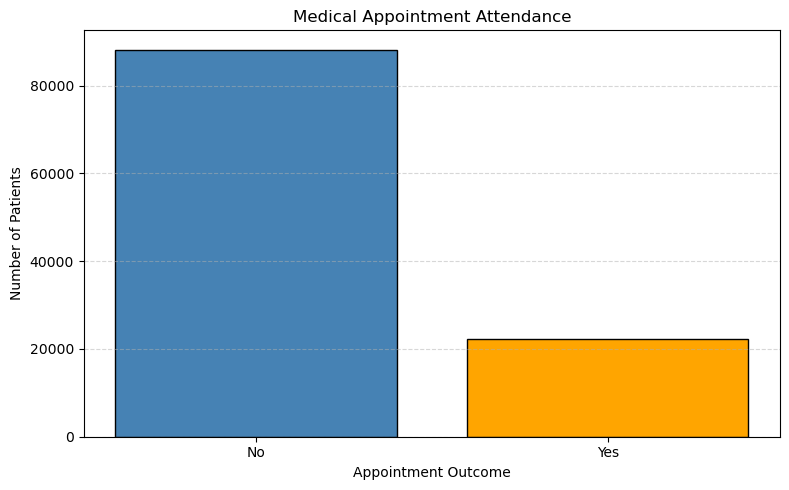

In [197]:
#Barchart

import matplotlib.pyplot as plt

no_show_count = df["No-show"].value_counts()

plt.figure(figsize=(8, 5))

plt.bar( no_show_count.index, no_show_count.values,color=["steelblue", "orange"], edgecolor="black")

plt.title("Medical Appointment Attendance")

plt.xlabel("Appointment Outcome")

plt.ylabel("Number of Patients")

plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()

plt.show()


#### 2. What is the distribution of patient ages?

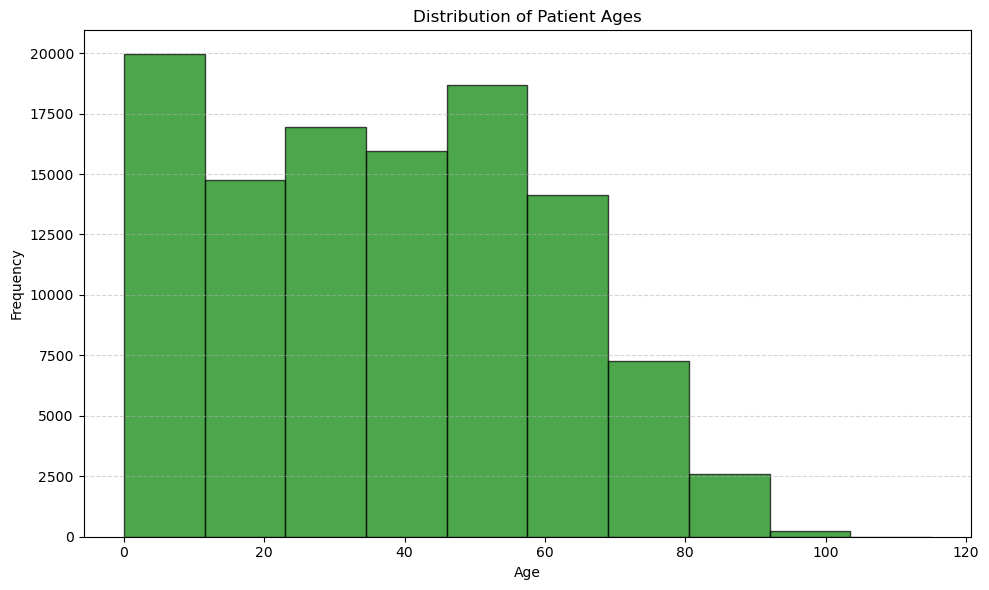

In [25]:
# Histogram

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.hist( df["Age"], bins=10, color="green", edgecolor="black", alpha=0.7)

plt.title("Distribution of Patient Ages")

plt.xlabel("Age")

plt.ylabel("Frequency")

plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()

plt.show()

#### 3. Which neighbourhoods have the most appointments?

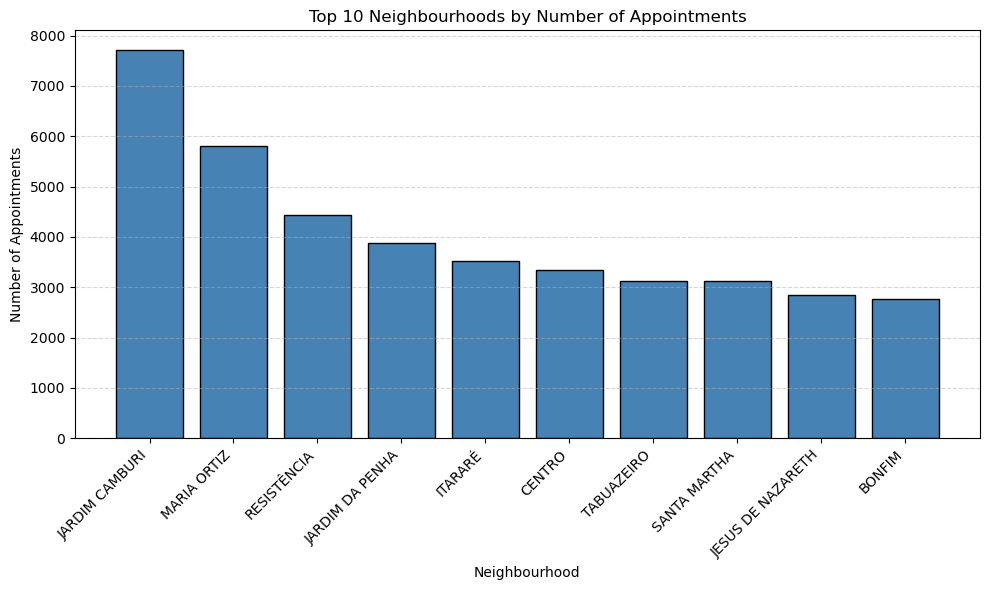

In [26]:
#Bar chart

import matplotlib.pyplot as plt

neighbourhood_count = (df["Neighbourhood"] .value_counts() .head(10))

plt.figure(figsize=(10, 6))

plt.bar( neighbourhood_count.index, neighbourhood_count.values, color="steelblue", edgecolor="black")

plt.title("Top 10 Neighbourhoods by Number of Appointments")

plt.xlabel("Neighbourhood")

plt.ylabel("Number of Appointments")

plt.xticks(rotation=45, ha="right")

plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()

plt.show()

The neighbourhood with the highest number of missed appointments was **JARDIM CAMBURI**, recording **1,465** no-shows. This was followed by **MARIA ORTIZ** (**1,219**), **ITARARÉ** (**923**), **RESISTÊNCIA** (**906**), and **CENTRO** (**703**). These neighbourhoods recorded the largest numbers of missed appointments in the dataset.

#### 4. How does age relate to appointment attendance?

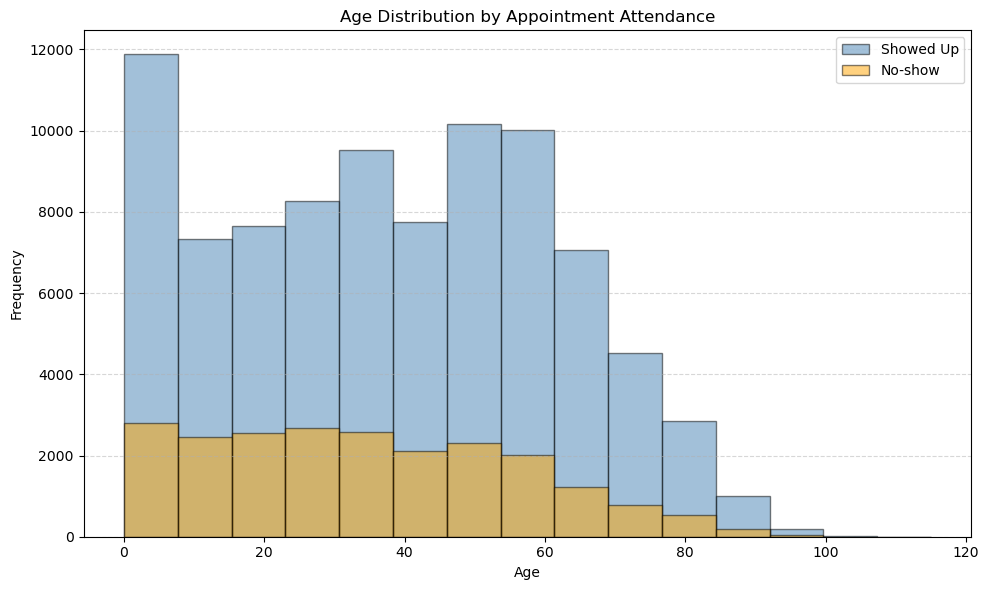

In [27]:
#Scatter plot
import matplotlib.pyplot as plt

showed_up = df[df["No-show"] == "No"]["Age"]
no_show = df[df["No-show"] == "Yes"]["Age"]

plt.figure(figsize=(10, 6))

plt.hist( showed_up, bins=15, alpha=0.5, color="steelblue", edgecolor="black", label="Showed Up")

plt.hist(no_show, bins=15, alpha=0.5, color="orange", edgecolor="black", label="No-show")

plt.title("Age Distribution by Appointment Attendance")

plt.xlabel("Age")

plt.ylabel("Frequency")

plt.legend()

plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()

plt.show()

#### 5. Does receiving an SMS relate to no-shows?

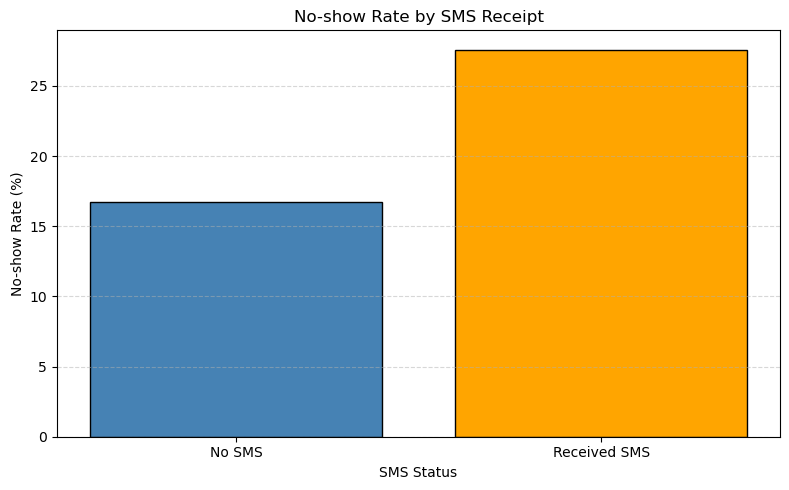

In [29]:
#Bar chart

import matplotlib.pyplot as plt

no_show_rate = ( df.groupby("SMS_received")["No-show"] .apply(lambda x: (x == "Yes").mean() * 100))

plt.figure(figsize=(8, 5))

plt.bar( ["No SMS", "Received SMS"], no_show_rate.values, color=["steelblue", "orange"], edgecolor="black")

plt.title("No-show Rate by SMS Receipt")

plt.xlabel("SMS Status")

plt.ylabel("No-show Rate (%)")

plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

#### 6. How does the waiting time between scheduling and appointment affect no-shows?

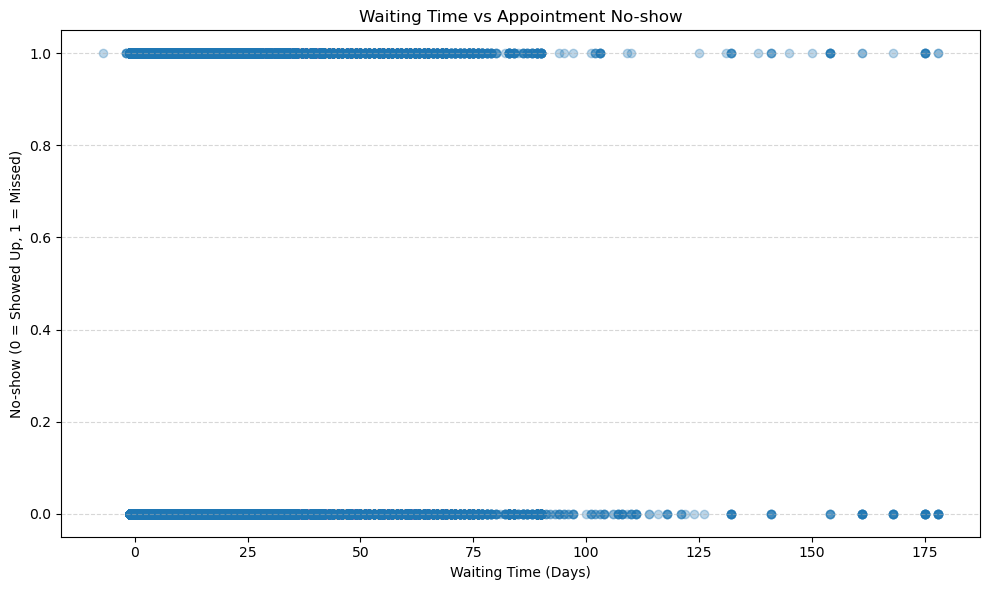

In [30]:
# Scatter plot
import matplotlib.pyplot as plt

waiting_days = (df["AppointmentDay"] - df["ScheduledDay"]).dt.days

plt.figure(figsize=(10, 6))

plt.scatter(waiting_days, df["No-show"].map({"No": 0, "Yes": 1}),alpha=0.3)

plt.title("Waiting Time vs Appointment No-show")

plt.xlabel("Waiting Time (Days)")

plt.ylabel("No-show (0 = Showed Up, 1 = Missed)")

plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()

plt.show()

#### 7. How do medical conditions such as hypertension or diabetes relate to attendance?

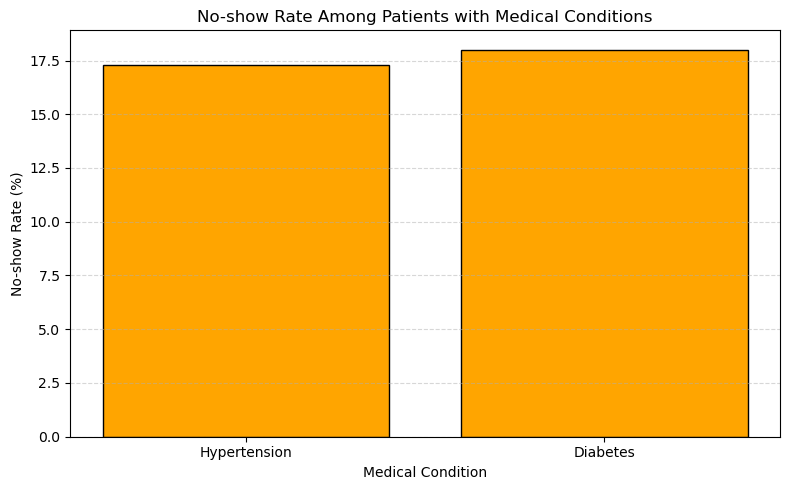

In [31]:
# Bar chart

import matplotlib.pyplot as plt

# Hypertension
hypertension_no_show = ( df[df["Hipertension"] == 1]["No-show"] .value_counts())

hypertension_total = ( df["Hipertension"] == 1).sum()

hypertension_rate = (hypertension_no_show.get("Yes", 0) / hypertension_total) * 100


# Diabetes
diabetes_no_show = (df[df["Diabetes"] == 1]["No-show"].value_counts())

diabetes_total = (df["Diabetes"] == 1).sum()

diabetes_rate = (diabetes_no_show.get("Yes", 0) / diabetes_total) * 100


# Plot
conditions = ["Hypertension", "Diabetes"]
no_show_rates = [hypertension_rate, diabetes_rate]

plt.figure(figsize=(8, 5))

plt.bar(conditions, no_show_rates, color="orange",edgecolor="black")

plt.title("No-show Rate Among Patients with Medical Conditions")

plt.xlabel("Medical Condition")

plt.ylabel("No-show Rate (%)")

plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()

plt.show()


#### 8. How does the waiting-time distribution differ between patients who attended and those who missed their appointments?

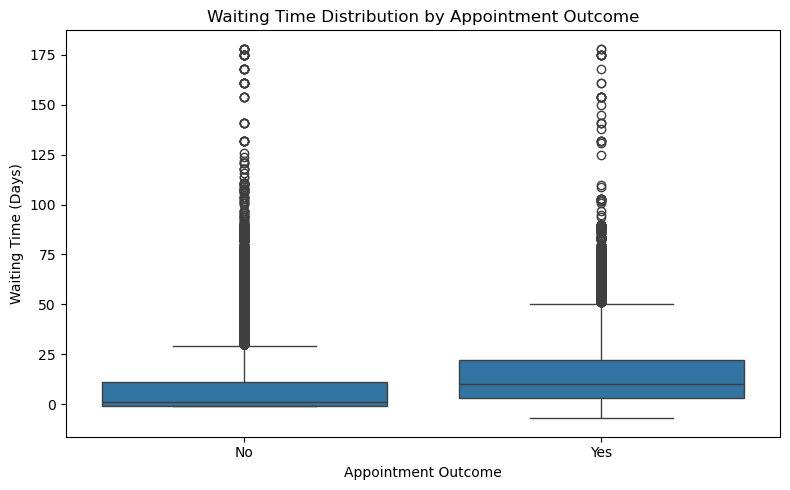

In [57]:

# Calculate waiting time using WaitingDays\calendar_wait
df["WaitingDays"] = ( df["AppointmentDay"] - df["ScheduledDay"]).dt.days

#boxplot
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))

sns.boxplot( data=df, x="No-show", y="WaitingDays")

plt.title("Waiting Time Distribution by Appointment Outcome")
plt.xlabel("Appointment Outcome")
plt.ylabel("Waiting Time (Days)")

plt.tight_layout()
plt.show()

#### 9. How does patient age distribution vary by SMS reminder status and appointment outcome?

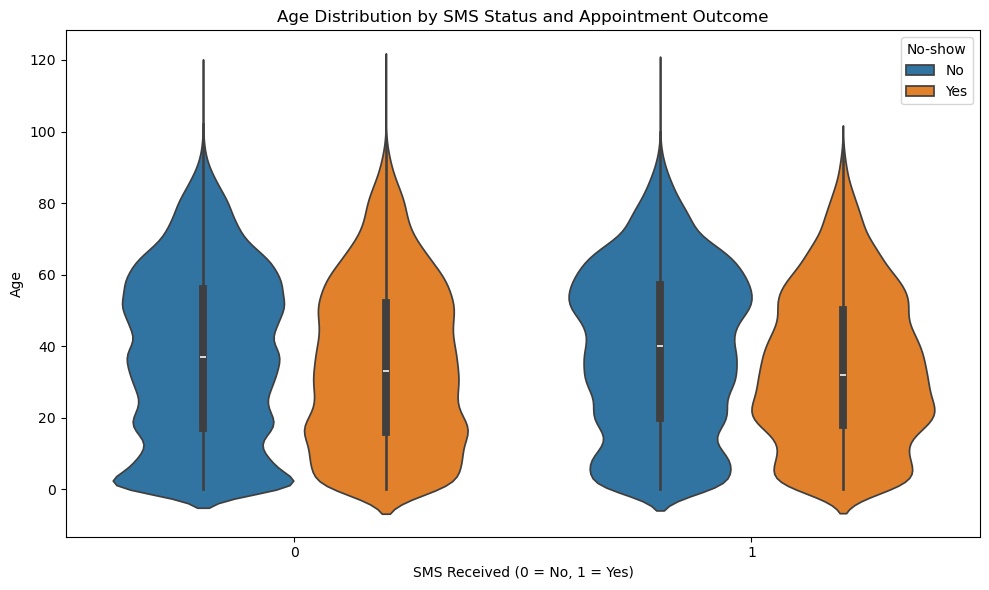

In [50]:
#violinplot

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

sns.violinplot( data=df, x="SMS_received", y="Age",  hue="No-show",inner="box")

plt.title("Age Distribution by SMS Status and Appointment Outcome")
plt.xlabel("SMS Received (0 = No, 1 = Yes)")
plt.ylabel("Age")

plt.tight_layout()
plt.show()

## Key Insights

- The dataset contains **110,526** medical appointments from **62,298** unique patients.
- **79.81%** of appointments were attended, while **20.19%** resulted in a No-show.
- Female patients accounted for the majority of appointments, with **71,839** appointments compared to **38,687** for male patients.
- The average patient age was approximately **37.09 years**.
- The **Adult** age group recorded the highest number of appointments (**37,761**), followed by **Young Adults** (**22,592**).
- Patients who received an SMS reminder had a higher proportion of missed appointments (**27.57%**) than those who did not receive an SMS reminder (**16.70%**). This represents an observed association and does not imply causation.
- Patients enrolled in the scholarship program recorded a slightly higher proportion of missed appointments (**23.74%**) than patients not enrolled (**19.81%**).
- **JARDIM CAMBURI** recorded the highest number of missed appointments (**1,465**), followed by **MARIA ORTIZ** (**1,219**) and **ITARARÉ** (**923**).

## Business Recommendations

- Monitor neighbourhoods with the highest numbers of missed appointments, such as **JARDIM CAMBURI**, to better understand local attendance patterns and allocate follow-up efforts where they are most needed.
- Review the effectiveness of the current SMS reminder process since patients who received reminders recorded a higher proportion of missed appointments. Additional investigation may help determine whether reminder timing or other factors influence attendance.
- Pay closer attention to patient groups with relatively higher no-show rates, such as scholarship beneficiaries, to better understand potential barriers to appointment attendance.
- Continue tracking appointment attendance across different age groups and patient characteristics to support data-driven planning and resource allocation.

## Separate Features x and Target y

In [69]:
# Before sepration, the original dataset contains 110,526, row and 15 columns to Separate
df.shape

(110526, 15)

##### We will not be using all the column for our separation and modelling, because data leakage or making deployment impractical. so we would exclude the folowing 

The  excluded columns are:
PatientId :      It identifies a patient, but the model might memorize patterns instead of learning generalizable behaviour.
AppointmentID :  It's an identifier, not a meaningful characteristic of an appointment.
SMS_received :   We don't know whether the SMS has been received at the moment we want to predict.
AppointmentDay : We already concluded it through WaitingDays
ScheduledDay :   We already concluded it through WaitingDays


In [70]:
# WE are doing the dropping here, drop columns not needed for modelling
df_model.drop(columns=[ "PatientId",  "AppointmentID",  "SMS_received", "ScheduledDay" "AppointmentDay"], inplace=True)

# confirming ( from 15, back to 11 now) 
df_model.shape

(110521, 11)

## Split Train and Test Data

In [85]:
# we import our ML library SkLearn, and select train test split from it ,it would allow us to test split our x,y into train\test set
from sklearn.model_selection import train_test_split

In [86]:
#here we splits our x, y into 80% : 20% ratio, 80% training data for learning and 20% testing data for evaluating the model,
#text_size = 0.2 means keep the test size 20% on each x,y
#random_state=42 makes sure we get the same split every time we run the code.
#stratify=When you divide the data, preserve the Target yes and No proportions in both the training and test sets, no miss-approprate (coz of imbalance) 

X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2, random_state=42, stratify=y)

# showing all the shape 
print("X_train:", X_train.shape) # showing the shape of x_train 80%
print("X_test:", X_test.shape) # showing the shape of x_test 20%
print("y_train:", y_train.shape) # showing the shape of y_train 80%
print("y_test:", y_test.shape) # showing the shape of y_test 20%

X_train: (88416, 10)
X_test: (22105, 10)
y_train: (88416,)
y_test: (22105,)


## Preprocessing, Encoding and Scaling

In [98]:
#Import preprocessing tools

# this import lib allow us to preprocess and encoding, by changing categorical column to numerical value and scaling by standardize the numerical features.e.g age
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# manager that directs each column to the correct processing method or decides which preprocessing method each column receives 
from sklearn.compose import ColumnTransformer

# combines preprocessing and model training into one workflow or connects them into one ordered workflow helping prevent data leakage.
from sklearn.pipeline import Pipeline

In [ ]:
NB : Our Target of y_train, y_test remain unchanged, preprocessing only apply to features of X_train, x_test.

In [99]:
#Assigning each column to their category , 2 variable was created 

# the numerical features, column that containt int\floats
numeric_features = ["Age", "WaitingDays"]

# the categorical features, column that contain object
categorical_features = ["Gender","Neighbourhood","AppointmentWeekday"]

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

# So our preprocessor is simply a converter (technically to numerical in backgrund so we can perform the heavy math)
# Create the preprocessing transformer that scaled the numerical features and converts categorical features into numerical values using OnehotEncoder.
# handle_unknown means handles a category in test or future data that wasn't present during training.
#remainder="passthrough": keeps all other columns unchanged, including your binary features.

# Create the preprocessing transformer
preprocessor = ColumnTransformer(transformers=[
        ("scale", StandardScaler(), numeric_features),
        ("encode", OneHotEncoder(handle_unknown="ignore"), categorical_features)], remainder="passthrough")

Numeric features: ['Age', 'WaitingDays']
Categorical features: ['Gender', 'Neighbourhood', 'AppointmentWeekday']


In [100]:
# here we created a variable (X_train_processed ) to wrap up or apply our preprocessing & conversions 
X_train_processed = preprocessor.fit_transform(X_train)

# here we created a variable (X_test_processed) to wrap up or apply our preprocessing & conversions 
#but using the existing apply rules to learned from the training data to transform the test data, we want it unseen so we use (.transform) only for data leakage
X_test_processed = preprocessor.transform(X_test)

print("X_train_processed:", X_train_processed.shape) #confirming the x_train  shape after preprocsesing (80% of df)
print("X_test_processed:", X_test_processed.shape) #confirming  the x_test shape after preprocessing (20% of df)

X_train_processed: (88416, 96)
X_test_processed: (22105, 96)


## Model Training, Prediction and Evaluation

For Architeture plan on our Model Algorithm, we're using the following

1. Logistic Regression : Baseline model; helps us understand how a relatively simple classifier performs.
2. Decision Tree	:    Learns rules and patterns, including nonlinear relationships.
3. Random Forest	:    Combines multiple decision trees to improve predictive performance and robustness.

and then hyperparameter tunning on each of the 3 Model again

### Logistic Regression Model

In [198]:
# Import Logistic Regression
from sklearn.linear_model import LogisticRegression

In [128]:
# Create and train the model and allows up to 1,000 iterations to find suitable parameters.
logreg_model = LogisticRegression(max_iter=1000)

# This will makes the model variable learn the relationship between the features (x_train_processed) and Target (y_train).
logreg_model.fit(X_train_processed, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [113]:
# using our reserved 20% feature df to test the model and predict using (logreg_model.predict) then answer to be store into logreg_pred variable
# Make predictions on the test data
logreg_pred = logreg_model.predict(X_test_processed)

#confirmimg the prediction, Display the first 10 predictions
print(logreg_pred[:10])

['No' 'No' 'No' 'No' 'No' 'No' 'No' 'No' 'No' 'No']


#### Evaluations on Logistics Regression Model

In [119]:
# Import evaluation metrics, the 4 metrics are (accuracy_score, classification_report, confusion_matrix, roc_auc_score)
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score

In [164]:
# Evaluate predictions for Accuracy Metrics
print("Accuracy:", accuracy_score(y_test, logreg_pred))


# Evaluate predictions for Classifications Report  metrics
print("\nClassification Report:")
print(classification_report(y_test, logreg_pred))


#Evaluate predictions for Confusion Matrix metrics
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, logreg_pred))


# Evaluate predictions for ROC_AUC Metrics (NB: we need to find the probalities first before getting the roc_auc, the score are the one that say) 
logreg_rocauc = roc_auc_score((y_test == "Yes").astype(int),logreg_model.predict_proba(X_test_processed)[:, list(logreg_model.classes_).index("Yes")])
print("\nLogistic Regression ROC-AUC:", logreg_rocauc)

Accuracy: 0.7954761366206741

Classification Report:
              precision    recall  f1-score   support

          No       0.80      0.99      0.89     17642
         Yes       0.36      0.02      0.03      4463

    accuracy                           0.80     22105
   macro avg       0.58      0.50      0.46     22105
weighted avg       0.71      0.80      0.71     22105


Confusion Matrix:
[[17507   135]
 [ 4386    77]]

Logistic Regression ROC-AUC: 0.6569231913850707


##### Output Explanation

Accuracy: 
79.55% — How often the model predicts correctly.

Classification Report:
- Precision (Yes): 36% — How many predicted no-shows were actually no-shows.
- Precision (No): 80% — How many predicted attendees actually attended.
- Recall    (Yes): 2% — How many actual no-shows the model detected.
- Recall    (No): 99% — How many actual attendees the model identified.
- F1-score  (Yes): 0.03% — A combined measure of precision and recall.
- F1-score  (NO): 89% — A combined measure of precision and recall.


Confusion Matrix:
- 17,507 - True Negative TN  or Actual No,  predicted No.  (Correctly predicted attended appointments)
- 135 -    False Positive FP or Actual No,  predicted Yes. (Attended appointments incorrectly predicted as no-shows)
- 4,386 -  False Negative FN or Actual Yes, predicted No.  ( Actual no-shows incorrectly predicted as attended) 
- 77 -     True Positive TP  or Actual Yes, predicted Yes. (Correctly predicted no-shows)


ROC-AUC:
0.657 —  approx = 65.7% How well the model distinguishes no show from who show, it also indicates modest ability to distinguish between the two classes across different probability thresholds..

### Decision Tree Classifier Model

In [122]:
# import DecisonTreeclassifier, Classifier type is for classification Machine learning Model
from sklearn.tree import DecisionTreeClassifier

In [123]:
# Create and train the model and random =  42 keep it the same output, each time we re-run
dectree_model = DecisionTreeClassifier(random_state=42)

# This will makes the model variable learn the relationship between the features (x_train_processed) and Target (y_train).
dectree_model.fit(X_train_processed, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [125]:
# using our reserved 20% feature df to test the model and predict using (dectree_model.predict) then answer to be store into dectree_pred variable
# Make predictions on the test data
dectree_pred = dectree_model.predict(X_test_processed)

#confirmimg the prediction, Display the first 10 predictions
print(dectree_pred[:10])

['No' 'No' 'No' 'No' 'No' 'No' 'No' 'No' 'No' 'No']


#### Evaluations on Decision Tree Classifier Model

In [121]:
# Import evaluation metrics, the 4 metrics are (accuracy_score, classification_report, confusion_matrix, roc_auc_score)
from sklearn.metrics import ( accuracy_score, classification_report, confusion_matrix, roc_auc_score)

In [165]:
# Evaluate predictions for Accuracy Metrics
print("Accuracy:", accuracy_score(y_test, dectree_pred))

# Evaluate predictions for Classifications Report  metrics
print("\nClassification Report:")
print(classification_report(y_test, dectree_pred))


#Evaluate predictions for Confusion Matrix metrics
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, dectree_pred))


# Evaluate predictions for ROC_AUC Metrics (NB: we need to find the probalities first before getting the roc_auc, the score are the one that say) 
dectree_rocauc = roc_auc_score( (y_test == "Yes").astype(int),dectree_model.predict_proba(X_test_processed)[:, list(dectree_model.classes_).index("Yes")])
print("\nDecision Tree ROC-AUC:", dectree_rocauc)

Accuracy: 0.7465731734901606

Classification Report:
              precision    recall  f1-score   support

          No       0.84      0.85      0.84     17642
         Yes       0.36      0.34      0.35      4463

    accuracy                           0.75     22105
   macro avg       0.60      0.59      0.60     22105
weighted avg       0.74      0.75      0.74     22105


Confusion Matrix:
[[14998  2644]
 [ 2958  1505]]

Decision Tree ROC-AUC: 0.5993296276787188


##### Output Explanation

Accuracy:  
74.66% — How often the model predicts correctly.

Classification Report:
- Precision (No): 84% — How many predicted attendees actually attended.
- Precision (Yes): 36% — How many predicted no-shows were actually no-shows.
- Recall    (No): 85% — How many actual attendees the model identified.
- Recall    (Yes): 34% — How many actual no-shows the model detected.
- F1-score  (No): 0.84 — A combined measure of precision and recall.
- F1-score  (Yes): 0.35 — A combined measure of precision and recall.
  
Confusion Matrix:
- 14,998 — True Negative (TN): Actual No, predicted No. (Correctly predicted attended appointments)
- 2,644 — False Positive (FP): Actual No, predicted Yes. (Attended appointments incorrectly predicted as no-shows)
- 2,958 — False Negative (FN): Actual Yes, predicted No. (Actual no-shows incorrectly predicted as attended)
- 1,505 — True Positive (TP): Actual Yes, predicted Yes. (Correctly predicted no-shows)

ROC-AUC:  
0.599 ≈ 59.9% — How well the model distinguishes no-shows from attendees across different probability thresholds. This indicates weak ability to distinguish between the two classes.


### Random Forest Model Classifier 

In [ ]:
# import DecisonTreeclassifier, Classifier type is for classification Machine learning Model
from sklearn.ensemble import RandomForestClassifier

In [140]:
# Creating thr model with the parameter of
# n_estimators=100: Builds 100 decision trees. 
# random_state=42: Makes results reproducible and 
# n_jobs=-1: Uses all available CPU cores for training.
rfc_model = RandomForestClassifier(n_estimators=100,random_state=42, n_jobs=-1)

# This will makes the model variable learn the relationship between the feature (x_train_processed) and target (y_train).
rfc_model.fit(X_train_processed, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [153]:
# using our reserved 20% feature df to test the model and predict using (rfc_model.predict) then answer to be store into rfc_pred variable
# Make predictions on the test data
rfc_pred = rfc_model.predict(X_test_processed)

#confirmimg the prediction, Display the first 10 predictions
print(rfc_pred[:10])

['No' 'No' 'No' 'No' 'No' 'No' 'No' 'No' 'No' 'No']


#### Evaluations on Random Forest Classifier Model

In [154]:
# Import evaluation metrics, the 4 metrics are (accuracy_score, classification_report, confusion_matrix, roc_auc_score)
from sklearn.metrics import (accuracy_score, classification_report,  confusion_matrix, roc_auc_score)

In [166]:
# Evaluate predictions for Accuracy Metrics
print("Accuracy:", accuracy_score(y_test, rfc_pred))


# Evaluate predictions for Classifications Report  metrics
print("\nClassification Report:")
print(classification_report(y_test, rfc_pred))


#Evaluate predictions for Confusion Matrix metrics
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rfc_pred))
yes_index = list(rfc_model.classes_).index("Yes")


# Evaluate predictions for ROC_AUC Metrics (NB: we need to find the probalities first before getting the roc_auc, the score are the one that say) 
rfc_rocauc = roc_auc_score((y_test == "Yes").astype(int),rfc_model.predict_proba(X_test_processed)[:, list(rfc_model.classes_).index("Yes")]) 
print("\nRandom Forest ROC-AUC:", rfc_rocauc)

Accuracy: 0.7783306944130287

Classification Report:
              precision    recall  f1-score   support

          No       0.83      0.91      0.87     17642
         Yes       0.42      0.25      0.31      4463

    accuracy                           0.78     22105
   macro avg       0.62      0.58      0.59     22105
weighted avg       0.74      0.78      0.76     22105


Confusion Matrix:
[[16094  1548]
 [ 3352  1111]]

Random Forest ROC-AUC: 0.7234922782577163



##### Output Explanation

Accuracy:  
77.83% — How often the model predicts correctly.

Classification Report:
- Precision (Yes): 42% — How many predicted no-shows were actually no-shows.
- Precision (No): 83% — How many predicted attendees actually attended.
- Recall    (Yes): 25% — How many actual no-shows the model detected.
- Recall    (No): 91% — How many actual attendees the model identified.
- F1-score  (Yes): 0.31 — A combined measure of precision and recall.
- F1-score  (No): 0.87 — A combined measure of precision and recall.

Confusion Matrix:
- 16,094 — True Negative (TN): Actual No, predicted No. (Correctly predicted attended appointments)
- 1,548 — False Positive (FP): Actual No, predicted Yes. (Attended appointments incorrectly predicted as no-shows)
- 3,352 — False Negative (FN): Actual Yes, predicted No. (Actual no-shows incorrectly predicted as attended)
- 1,111 — True Positive (TP): Actual Yes, predicted Yes. (Correctly predicted no-shows)

ROC-AUC:  
0.723 ≈ 72.3% — How well the model distinguishes no-shows from attendees across different probability thresholds. This indicates a moderate ability to distinguish between the two classes.

### Model Comparison and Hyperparameter Tuning

In [167]:
# Create a table to compare the performance of all four models
# Accuracy measures overall correctness; Precision, Recall and F1 focus on no-show detected


model_comparison = pd.DataFrame({

 "Model": ["Logistic Regression", "Decision Tree", "Random Forest"],

 "Accuracy": [ accuracy_score(y_test, logreg_pred), accuracy_score(y_test, dectree_pred),accuracy_score(y_test, rfc_pred)  ],

  "Precision": [precision_score(y_test, logreg_pred, pos_label="Yes"),precision_score(y_test, dectree_pred, pos_label="Yes"),precision_score(y_test, rfc_pred, pos_label="Yes") ],

  "Recall": [recall_score(y_test, logreg_pred, pos_label="Yes"),recall_score(y_test, dectree_pred, pos_label="Yes"), recall_score(y_test, rfc_pred, pos_label="Yes") ],

 "F1":  [f1_score(y_test, logreg_pred, pos_label="Yes"),f1_score(y_test, dectree_pred, pos_label="Yes"), f1_score(y_test, rfc_pred, pos_label="Yes") ],
    
"ROC-AUC": [logreg_rocauc, dectree_rocauc, rfc_rocauc]

})

    
# Display the comparison table
#display the table
model_comparison

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.795476,0.363208,0.017253,0.032941,0.656923
1,Decision Tree,0.746573,0.362738,0.337217,0.349512,0.599330
2,Random Forest,0.778331,0.417826,0.248936,0.311991,0.723492


##### Best Model: Random Forest Classifier Model

Random Forest achieved the highest ROC-AUC score of 0.723 among the three models, indicating the best overall ability to distinguish between patients who attended and those who missed appointments. However, its recall for no-shows was only 25%, meaning it detected just 1 in 4 actual no-shows. We will tune this model to see if its performance can be improved.

#### Random Forest Classifier Model Hyperparameter Tuning

Hyperparameter tuning involves testing different model settings to find the combination that improves prediction performance. We will tune Random Forest because it achieved the highest ROC-AUC among our three models.

We selected Random Forest for hyperparameter tuning because it achieved the highest ROC-AUC score among the three baseline models. Rather than tuning every model immediately, we focused on improving the strongest overall candidate first.

If the tuned Random Forest does not provide satisfactory performance, we might also tune Logistic Regression and Decision Tree and compare their results to determine whether either model offers a better balance of accuracy, precision, recall, F1-score, and ROC-AUC.

In [171]:
# Import the tool for testing different hyperparameter combinations
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier

In [172]:
# Define the settings to test by creating param_dist var we would later use in tunning (it also takes another param & kwargs)


# Define the hyperparameter values RandomizedSearchCV can choose from
param_dist = {
    "n_estimators": [50],             # Number of trees to build
    "max_depth": [10, 20, None],      # Maximum depth of each tree; None allows full growth
    "min_samples_split": [2, 10],     # Minimum samples needed to split a node
    "min_samples_leaf": [1, 5],       # Minimum samples allowed in a leaf node
    "max_features": ["sqrt", 0.5],    # Features considered at each split
    "class_weight": [None, "balanced"] # handling class imbalanced, Option to give more weight to the minority class
}


# Set up the search to test selected combinations using cross-validation

rf_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=42, n_jobs=1), # Keep results reproducible  and Let the search manage parallel processing
    param_distributions=param_dist,  # Hyperparameter options to explore
    n_iter=4,                        # n_iter=4 means only four combinations are tested, not every possible combination.
    cv=3,                            # Use 3-fold cross-validation for each combination
    scoring="roc_auc",               # Select settings with the highest ROC-AUC
    random_state=42,                 # Make the sampled combinations reproducible
    n_jobs=-1,                       # Use available CPU cores for the search
    verbose=1                        # Display progress while fitting
)

In [173]:
# Train and compare the selected combinations using training data only
rfc_search.fit(X_train_processed, y_train)

# Display the hyperparameter combination with the best average CV score
print("Best Parameters:", rfc_search.best_params_)

# Display its average ROC-AUC across the cross-validation folds
print("Best Cross-Validation ROC-AUC:", round(rfc_search.best_score_, 3))


Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best Parameters: {'n_estimators': 50, 'min_samples_split': 10, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': None, 'class_weight': 'balanced'}
Best Cross-Validation ROC-AUC: 0.739


##### Evaluations on Decision Tree Classifier Model hyperparameter tunning

In [174]:
# Import evaluation metrics, the 4 metrics are (accuracy_score, classification_report, confusion_matrix, roc_auc_score)
from sklearn.metrics import ( accuracy_score, classification_report, confusion_matrix, roc_auc_score)

In [178]:
# Choose the best model from the tunning setting search we have defined above,stored in rfc_search var

# Retrieve the best Random Forest model found during tuning
best_rfc_model = rfc_search.best_estimator_

# Predict whether each test appointment will be a no-show
tuned_rfc_pred = best_rfc_model.predict(X_test_processed)

# Get the probability of a no-show for each test appointment in order to get the ROC_AUC
yes_index_proba = list(best_rfc_model.classes_).index("Yes")
tuned_rfc_proba = best_rfc_model.predict_proba(X_test_processed)[:, yes_index_proba]

In [181]:

# For Accuracy Metrics : Evaluate overall prediction accuracy
print("\nAccuracy:", accuracy_score(y_test, tuned_rfc_pred))

# for Classification report: Evaluate precision, recall and F1-score for both classes
print("\nClassification Report:")
print(classification_report(y_test, tuned_rfc_pred))


# For Confusion Matrix : Show correct and incorrect predictions for each class
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, tuned_rfc_pred))


# For ROC_AUC: Measure how well the model distinguishes no-shows from attendees
tuned_rfc_rocauc = roc_auc_score((y_test == "Yes").astype(int), tuned_rfc_proba)
print("\nROC-AUC:", tuned_rfc_rocauc)


Accuracy: 0.6492648722008595

Classification Report:
              precision    recall  f1-score   support

          No       0.90      0.63      0.74     17642
         Yes       0.33      0.71      0.45      4463

    accuracy                           0.65     22105
   macro avg       0.61      0.67      0.60     22105
weighted avg       0.78      0.65      0.68     22105


Confusion Matrix:
[[11168  6474]
 [ 1279  3184]]

ROC-AUC: 0.7370613846639323


##### Output Explanation

Accuracy:  
64.93% — How often the model predicts correctly.

Classification Report:
- Precision (Yes): 33% — How many predicted no-shows were actually no-shows.
- Precision (No): 90% — How many predicted attendees actually attended.
- Recall (Yes): 71% — How many actual no-shows the model detected.
- Recall (No): 63% — How many actual attendees the model identified.
- F1-score (Yes): 0.45 — A combined measure of precision and recall.
- F1-score (No): 0.74 — A combined measure of precision and recall.

Confusion Matrix:
- 11,168 — True Negative (TN): Actual No, predicted No. (Correctly predicted attended appointments)
- 6,474 — False Positive (FP): Actual No, predicted Yes. (Attended appointments incorrectly predicted as no-shows)
- 1,279 — False Negative (FN): Actual Yes, predicted No. (Actual no-shows incorrectly predicted as attended)
- 3,184 — True Positive (TP): Actual Yes, predicted Yes. (Correctly predicted no-shows)

ROC-AUC:  
0.737 ≈ 73.7% — How well the model distinguishes no-shows from attendees across different probability thresholds. This indicates a moderate ability to distinguish between the two classes.

## Final Model and New Predictions

In [183]:
# It is noted that alll the 4 metrics are used, Acuuracy, Classification report,Confusion matrix, Roc-Auc result are what we are using for comparison


# Create a final comparison table showing the 2 model results, the original VS tuned Random Forest model
model_comparison_rf = pd.DataFrame({
    
"Model": ["Original Random Forest", "Tuned Random Forest"],
    
"Accuracy": [accuracy_score(y_test, rfc_pred),accuracy_score(y_test, tuned_rfc_pred) ],

"Precision": [ precision_score(y_test, rfc_pred, pos_label="Yes"), precision_score(y_test, tuned_rfc_pred, pos_label="Yes") ],

 "Recall": [ recall_score(y_test, rfc_pred, pos_label="Yes"), recall_score(y_test, tuned_rfc_pred, pos_label="Yes") ],

"F1": [ f1_score(y_test, rfc_pred, pos_label="Yes"), f1_score(y_test, tuned_rfc_pred, pos_label="Yes") ],

 "ROC-AUC": [ rfc_rocauc, tuned_rfc_rocauc ]})


# Display the comparison rounded to three decimal places
model_comparison_rf.round(3)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Original Random Forest,0.778,0.418,0.249,0.312,0.723
1,Tuned Random Forest,0.649,0.330,0.713,0.451,0.737


Final Model Selection

The tuned Random Forest best_rfc_model, was selected as the final model because it achieved a ROC-AUC score of 0.737 and a no-show recall of approximately 71%. Compared with the original Random Forest, it detected more patients who missed their appointments, although its overall accuracy and precision were lower. The model will be used to demonstrate predictions on new appointment records.
The tuned Random Forest is more suitable if the clinic prioritizes identifying patients at risk of missing appointments. However, its lower precision means staff may need to follow up with many patients who would have attended.

##### New Prediction

In [187]:
# we stored the selected final model "best_rfc_model" into a varibale called final_model
final_model = best_rfc_model

In [191]:

# Select 7 appointment from the processed test dataset (20% feature df)
sample_appointment = X_test_processed[0:7]

# Predict the outcome for all 7 appointments using the var sample_appointment
sample_prediction = final_model.predict(sample_appointment)

# Get the position of "Yes" in the model's class list
yes_index_proba = list(final_model.classes_).index("Yes")

# Get the no-show probability for each appointment
sample_probability = final_model.predict_proba( sample_appointment)[:, yes_index_proba]

# loop through and Display each prediction, probability and actual outcome
for i in range(7): 
    print(f"\nAppointment {i + 1}")  # Display the appointment number
    print("Predicted outcome:", sample_prediction[i])   # Display predicted class
    print(f"No-show probability: {sample_probability[i]:.2%}") #turn the probability to decimal percent e.g  48.94%
    print("Actual outcome:", y_test.iloc[i])  #y_test.iloc[i] retrieves the true outcome of the first 7 appointment in the y_test target.




Appointment 1
Predicted outcome: Yes
No-show probability: 58.46%
Actual outcome: Yes

Appointment 2
Predicted outcome: No
No-show probability: 48.94%
Actual outcome: No

Appointment 3
Predicted outcome: Yes
No-show probability: 60.80%
Actual outcome: No

Appointment 4
Predicted outcome: No
No-show probability: 44.65%
Actual outcome: No

Appointment 5
Predicted outcome: No
No-show probability: 7.33%
Actual outcome: No

Appointment 6
Predicted outcome: No
No-show probability: 9.30%
Actual outcome: No

Appointment 7
Predicted outcome: Yes
No-show probability: 52.60%
Actual outcome: No


#### Prediction Exports

In [192]:
# Create a DataFrame comparing all test predictions with actual outcomes
prediction_results = pd.DataFrame({"Actual Outcome": y_test,"Predicted Outcome": final_model.predict(X_test_processed)})

# Add the predicted probability of a no-show
yes_index_proba = list(final_model.classes_).index("Yes")

prediction_results["No-show Probability"] = (final_model.predict_proba(X_test_processed)[:, yes_index_proba])

# Add a column showing whether each prediction was correct
prediction_results["Correct Prediction"] = ( prediction_results["Actual Outcome"]== prediction_results["Predicted Outcome"])

# Display the first 7 results
prediction_results.head(7)

,Actual Outcome,Predicted Outcome,No-show Probability,Correct Prediction
82811,Yes,Yes,0.584571,True
58888,No,No,0.489362,True
107939,No,Yes,0.608009,False
79682,No,No,0.446493,True
62676,No,No,0.073317,True
13152,No,No,0.093008,True
21885,No,Yes,0.525981,False


In [193]:
# Export all test predictions and actual outcomes to a CSV file
prediction_results.to_csv("appointment_predictions.csv", index=False)

## Deployment

In [194]:
# Import joblib to save and load our trained model and preprocessor engine
import joblib

In [195]:

# Save the final trained model
joblib.dump(final_model, "Medical_Appoint_Noshow.pkl")

# Save the fitted preprocessing pipeline
joblib.dump(preprocessor, "preprocessor.pkl")

['preprocessor.pkl']

In [196]:
# Import OS to work with files and folders in the operating systemimport os
import os

# List all files and folders in the current working directory
os.listdir()

['.ipynb_checkpoints',
 'appointment_predictions.csv',
 'KaggleV2-May-2016.csv',
 'Medical_Appointment_ No_Show_Prediction_ML.ipynb',
 'Medical_Appoint_Noshow.pkl',
 'preprocessor.pkl']